<a href="https://colab.research.google.com/github/CatalinaPopa9/MEDE_U3_Seceta/blob/main/CP3_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MEDE · CP3 · PCA (baseline) vs UMAP vs CCA · U3 Secetă 2022
Rulează celulele în ordine. Nu există date mock: dacă lipsește un fișier, codul se oprește cu eroare.

In [35]:
# A: setup + GEE
!pip -q install umap-learn
import os, re, unicodedata, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import ee, google.auth
from google.colab import auth
warnings.filterwarnings('ignore')
auth.authenticate_user()
credentials, _ = google.auth.default()
ee.Initialize(credentials, project='mede-seceta-cp3')
print('GEE ok')

GEE ok


In [36]:
import os, shutil
os.chdir('/content')   # aici sunt CSV-urile tale din panoul din stânga

# redenumește fișierul de floarea-soarelui, cum îl așteaptă notebook-ul
if os.path.exists('date_ins_floare.csv') and not os.path.exists('date_ins_floarea.csv'):
    shutil.copy('date_ins_floare.csv', 'date_ins_floarea.csv')

for f in ['date_ins_porumb.csv', 'date_ins_grau.csv', 'date_ins_floarea.csv', 'date_ins_orz.csv']:
    print(f, '→', 'OK' if os.path.exists(f) else 'LIPSEȘTE')

# primele rânduri din fiecare, ca să verifici formatul (trebuie 3 coloane: Judet;An;valoare)
for f in ['date_ins_porumb.csv', 'date_ins_grau.csv', 'date_ins_floarea.csv', 'date_ins_orz.csv']:
    if os.path.exists(f):
        print('\n', f); print(open(f, encoding='utf-8', errors='ignore').read()[:300])

date_ins_porumb.csv → OK
date_ins_grau.csv → OK
date_ins_floarea.csv → OK
date_ins_orz.csv → OK

 date_ins_porumb.csv
Judet; An; INS_Randament_Porumb
 Bihor;2018;7503
 Bihor;2019;7519
 Bihor;2020;6582
 Bihor;2021;6300
 Bihor;2022;2934
 Bistrita-Nasaud;2018;5649
 Bistrita-Nasaud;2019;5185
 Bistrita-Nasaud;2020;4471
 Bistrita-Nasaud;2021;5264
 Bistrita-Nasaud;2022;5023
 Cluj;2018;8015
 Cluj;2019;6097
 Cluj;2020;5555


 date_ins_grau.csv
 Judet; An; Valoare
 Bihor; 2018;4172
 Bihor; 2019;4360
 Bihor; 2020;4073
 Bihor; 2021;4172
 Bihor; 2022;3834
 Bistrita-Nasaud; 2018;3179
 Bistrita-Nasaud; 2019;3274
 Bistrita-Nasaud; 2020;3784
 Bistrita-Nasaud; 2021;4075
 Bistrita-Nasaud; 2022;3904
 Cluj; 2018;4132
 Cluj; 2019;4148
 Cluj; 2020;3111

 date_ins_floarea.csv
Judet; An; Valoare
 Bihor; 2018;2069
 Bihor; 2019;2887
 Bihor; 2020;2369
 Bihor; 2021;2132
 Bihor; 2022;1620
 Bistrita-Nasaud; 2018;2131
 Bistrita-Nasaud; 2019;3114
 Bistrita-Nasaud; 2020;2151
 Bistrita-Nasaud; 2021;2282
 Bistrita-Nasaud

In [37]:
# B: extragere satelit (NDVI lunar, doar teren arabil) + meteo (T și bilanț P-PET lunar)
ANI = [2018, 2019, 2020, 2021, 2022]
LUNI = [4, 5, 6, 7, 8, 9]            # aprilie–septembrie
judete_ro = ee.FeatureCollection("FAO/GAUL/2015/level1").filter(ee.Filter.eq('ADM0_NAME', 'Romania'))
# mască teren arabil (MODIS Land Cover, clasa 12 = cropland), anul 2020 ca referință fixă
crop = (ee.ImageCollection("MODIS/061/MCD12Q1").filterDate('2020-01-01', '2020-12-31')
        .first().select('LC_Type1').eq(12))

def img_ndvi(an):
    bands = []
    for m in LUNI:
        ini = ee.Date.fromYMD(an, m, 1)
        b = (ee.ImageCollection("MODIS/061/MOD13Q1").filterDate(ini, ini.advance(1, 'month'))
             .select('NDVI').mean().multiply(0.0001).rename(f'NDVI_{m:02d}'))
        bands.append(b)
    return ee.Image.cat(bands).updateMask(crop)

def img_meteo(an):
    bands = []
    for m in LUNI:
        ini = ee.Date.fromYMD(an, m, 1)
        e = ee.ImageCollection("ECMWF/ERA5_LAND/MONTHLY_AGGR").filterDate(ini, ini.advance(1, 'month')).first()
        t = e.select('temperature_2m').subtract(273.15).rename(f'T_{m:02d}')
        # bilanț climatic (mm) = precipitații − |PET|; în ERA5-Land PET are semn negativ, deci folosim abs
        bh = (e.select('total_precipitation_sum').subtract(e.select('potential_evaporation_sum').abs())
              .multiply(1000).rename(f'BH_{m:02d}'))
        bands += [t, bh]
    return ee.Image.cat(bands)

def zonal(img, scale, an):
    feats = img.reduceRegions(collection=judete_ro, reducer=ee.Reducer.mean(), scale=scale).getInfo()['features']
    rows = []
    for f in feats:
        p = f['properties']
        r = {'Judet': p.get('ADM1_NAME'), 'An': an}
        r.update({k: v for k, v in p.items() if k.startswith(('NDVI_', 'T_', 'BH_'))})
        rows.append(r)
    return pd.DataFrame(rows)

if os.path.exists('df_sat.csv') and os.path.exists('df_met.csv'):
    df_sat, df_met = pd.read_csv('df_sat.csv'), pd.read_csv('df_met.csv')   # cache, evită reapelarea GEE
else:
    df_sat = pd.concat([zonal(img_ndvi(a), 250, a) for a in ANI], ignore_index=True)
    df_met = pd.concat([zonal(img_meteo(a), 9000, a) for a in ANI], ignore_index=True)
    df_sat.to_csv('df_sat.csv', index=False); df_met.to_csv('df_met.csv', index=False)
print(df_sat.shape, df_met.shape)

(205, 8) (205, 14)


In [38]:
# C: INS (un CSV per cultură, format: Judet;An;valoare, kg/ha)
INS_FISIERE = {'INS_Porumb': 'date_ins_porumb.csv',          # obligatoriu
               'INS_Grau': 'date_ins_grau.csv',
               'INS_FloareaSoarelui': 'date_ins_floarea.csv',
               'INS_Orz': 'date_ins_orz.csv'}
ins_list = []
for nume, fis in INS_FISIERE.items():
    if not os.path.exists(fis):
        if nume == 'INS_Porumb':
            raise FileNotFoundError('Lipsește date_ins_porumb.csv')
        print('Lipsește (omis):', fis); continue
    d = pd.read_csv(fis, sep=';', skipinitialspace=True)
    assert d.shape[1] == 3, f'{fis}: aștept 3 coloane, am {d.shape[1]}: {list(d.columns)}'
    d.columns = ['Judet', 'An', nume]                       # ← nume, nu 'Valoare'
    d['Judet'] = d['Judet'].astype(str).str.strip()
    d['An'] = pd.to_numeric(d['An'], errors='coerce').astype(int)
    d[nume] = pd.to_numeric(d[nume], errors='coerce')
    ins_list.append(d)
    print(nume, d.shape, 'județe:', d.Judet.nunique())
print('Culturi INS încărcate:', [d.columns[-1] for d in ins_list])

INS_Porumb (205, 3) județe: 41
INS_Grau (206, 3) județe: 42
INS_FloareaSoarelui (198, 3) județe: 41
INS_Orz (205, 3) județe: 41
Culturi INS încărcate: ['INS_Porumb', 'INS_Grau', 'INS_FloareaSoarelui', 'INS_Orz']


In [39]:
# D: potrivire nume județe + matrice finală
def cheie(s):
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().lower()
    s = re.sub(r'municipiul|judetul|county', '', s)
    return re.sub(r'[^a-z]', '', s)

ALIAS = {'bucuresti': 'bucharest'}     # completează după ce vezi diagnosticul de mai jos

def adauga_cheie(d):
    d = d.copy(); d['K'] = d['Judet'].map(cheie).replace(ALIAS); return d

df_sat, df_met = adauga_cheie(df_sat), adauga_cheie(df_met)
ins_k = [adauga_cheie(d).drop(columns='Judet') for d in ins_list]
df_ins = ins_k[0]
for d in ins_k[1:]:
    df_ins = df_ins.merge(d, on=['K', 'An'], how='outer')

# diagnostic: ce chei nu se regăsesc în toate sursele
print('Doar în INS      :', sorted(set(df_ins.K) - set(df_sat.K)))
print('Doar în GAUL/GEE :', sorted(set(df_sat.K) - set(df_ins.K)))

mat = (df_sat.merge(df_met.drop(columns='Judet'), on=['K', 'An'], how='outer')
             .merge(df_ins, on=['K', 'An'], how='outer'))
print('Chei distincte:', mat.K.nunique(), '| rânduri:', len(mat))

Doar în INS      : ['dambovita', 'ilfov', 'valcea']
Doar în GAUL/GEE : ['dimbovita', 'vilcea']
Chei distincte: 44 | rânduri: 220


Rânduri complete: 182 din 220 | județe complete: 37
Goluri pe coloană:
 NDVI_04                15
NDVI_05                15
NDVI_06                15
NDVI_07                15
NDVI_08                15
NDVI_09                15
BH_04                  15
BH_05                  15
BH_06                  15
BH_07                  15
BH_08                  15
BH_09                  15
T_04                   15
T_05                   15
T_06                   15
T_07                   15
T_08                   15
T_09                   15
INS_Porumb             15
INS_Grau               14
INS_FloareaSoarelui    22
INS_Orz                15
dtype: int64


,sursa,count,mean,std,min,50%,max
NDVI_04,satelit,182.0,0.533,0.066,0.399,0.528,0.692
NDVI_05,satelit,182.0,0.648,0.058,0.426,0.652,0.753
NDVI_06,satelit,182.0,0.663,0.069,0.431,0.680,0.805
NDVI_07,satelit,182.0,0.628,0.098,0.387,0.651,0.771
NDVI_08,satelit,182.0,0.549,0.103,0.314,0.552,0.741
NDVI_09,satelit,182.0,0.476,0.094,0.307,0.468,0.688
BH_04,meteo,182.0,-138.034,66.998,-294.321,-126.375,12.072
BH_05,meteo,182.0,-139.386,76.345,-291.611,-147.645,95.766
BH_06,meteo,182.0,-120.011,82.982,-346.818,-127.353,50.276
BH_07,meteo,182.0,-179.249,87.088,-446.019,-185.511,9.629


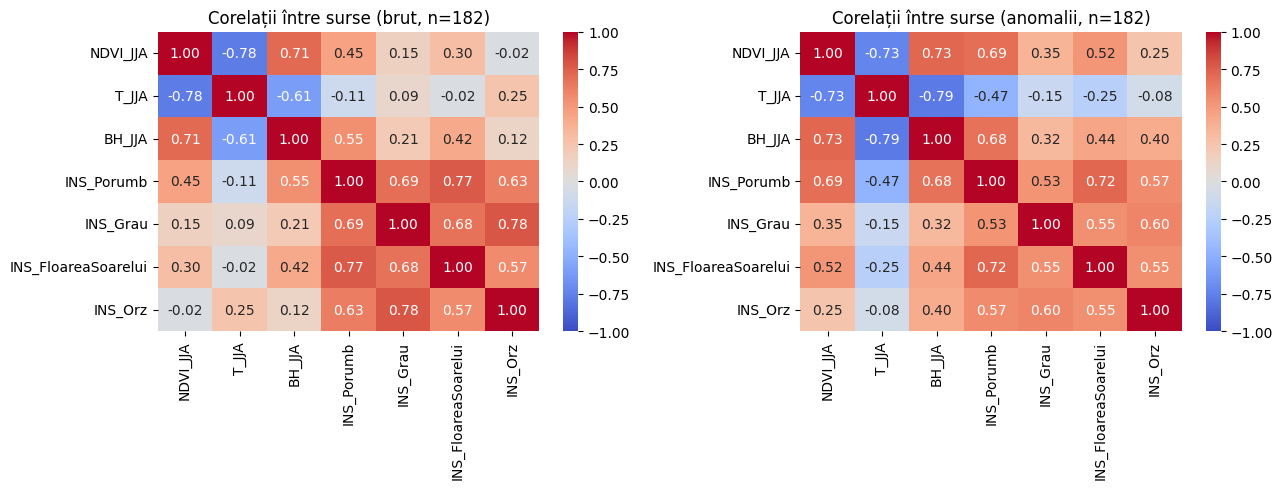

In [40]:
# E: grupuri de trăsături pe sursă + matrice completă + statistici descriptive
VIEWS = {'satelit': [c for c in mat if c.startswith('NDVI_')],
         'meteo':   [c for c in mat if c.startswith(('T_', 'BH_'))],
         'ins':     [c for c in mat if c.startswith('INS_')]}
TOATE = sum(VIEWS.values(), [])
cu_goluri = mat[mat[TOATE].isna().any(axis=1)]
D0 = mat.dropna(subset=TOATE).reset_index(drop=True)
print(f'Rânduri complete: {len(D0)} din {len(mat)} | județe complete: {D0.K.nunique()}')
print('Goluri pe coloană:\n', mat[TOATE].isna().sum()[lambda s: s > 0])

def anomalii(df, cols):
    g = df.groupby('K')[cols]
    return (df[cols] - g.transform('mean')) / g.transform('std')

D1 = D0.copy()
D1[TOATE] = anomalii(D0, TOATE)
D1 = D1.dropna(subset=TOATE).reset_index(drop=True)
VARIANTE = {'brut': D0, 'anomalii': D1}

desc = D0[TOATE].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']]
desc.insert(0, 'sursa', [next(v for v, c in VIEWS.items() if col in c) for col in desc.index])
display(desc.round(3))
D0.to_csv('matrice_X.csv', index=False); desc.to_csv('statistici_descriptive.csv')

# corelații între surse, pe rezumate sezoniere (iun–aug)
def rezumat(D):
    r = pd.DataFrame({'NDVI_JJA': D[['NDVI_06', 'NDVI_07', 'NDVI_08']].mean(axis=1),
                      'T_JJA': D[['T_06', 'T_07', 'T_08']].mean(axis=1),
                      'BH_JJA': D[['BH_06', 'BH_07', 'BH_08']].sum(axis=1)})
    for c in VIEWS['ins']: r[c] = D[c]
    return r
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, (nume, D) in zip(ax, VARIANTE.items()):
    sns.heatmap(rezumat(D).corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=a)
    a.set_title(f'Corelații între surse ({nume}, n={len(D)})')
plt.tight_layout(); plt.savefig('fig_corelatii_surse.png', dpi=150); plt.show()

In [41]:
# F: protocol – PCA (baseline), UMAP, CCA
import umap
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import CCA
from sklearn.manifold import trustworthiness
from scipy.linalg import subspace_angles

K_NN, SEEDS = 10, range(10)
def Z_of(D, cols): return StandardScaler().fit_transform(D[cols])

def eval_pca(D, cols):
    Z = Z_of(D, cols); k = min(2, Z.shape[1])
    p = PCA(n_components=k).fit(Z); T = p.transform(Z)
    full = PCA().fit(Z).explained_variance_ratio_.cumsum()
    return dict(n_trasaturi=len(cols), pca_var2=p.explained_variance_ratio_.sum(),
                pca_comp_80=int(np.argmax(full >= 0.8) + 1),
                pca_recon_mse=((Z - p.inverse_transform(T)) ** 2).mean(),
                pca_trust=trustworthiness(Z, T, n_neighbors=K_NN) if k == 2 else np.nan)

def eval_umap(D, cols):
    if len(cols) < 3: return dict(umap_trust_mean=np.nan, umap_trust_sd=np.nan)
    Z = Z_of(D, cols)
    t = [trustworthiness(Z, umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=s).fit_transform(Z),
                         n_neighbors=K_NN) for s in SEEDS]
    return dict(umap_trust_mean=np.mean(t), umap_trust_sd=np.std(t))

def unghi_subperioade(D, cols):
    if len(cols) < 2: return np.nan
    a, b = D[D.An <= 2020], D[D.An >= 2021]
    pa, pb = PCA(2).fit(Z_of(a, cols)), PCA(2).fit(Z_of(b, cols))
    return float(np.degrees(subspace_angles(pa.components_.T, pb.components_.T)).max())

def cca_loyo(D, A, B):
    out = {}
    for y in sorted(D.An.unique()):
        tr, te = D.An != y, D.An == y
        sa, sb = StandardScaler().fit(D.loc[tr, A]), StandardScaler().fit(D.loc[tr, B])
        m = CCA(n_components=1, max_iter=1000).fit(sa.transform(D.loc[tr, A]), sb.transform(D.loc[tr, B]))
        u, v = m.transform(sa.transform(D.loc[te, A]), sb.transform(D.loc[te, B]))
        out[int(y)] = float(np.corrcoef(u[:, 0], v[:, 0])[0, 1])
    return out

REZ, CCA_REZ = {}, {}
for var, D in VARIANTE.items():
    vw = {**VIEWS, 'combinat': TOATE}
    REZ[var] = pd.DataFrame({n: {**eval_pca(D, c), **eval_umap(D, c), 'unghi_subperioade_grade': unghi_subperioade(D, c)}
                             for n, c in vw.items()}).T
    CCA_REZ[var] = cca_loyo(D, VIEWS['satelit'], VIEWS['meteo'])
    REZ[var].to_csv(f'rezultate_CP3_{var}.csv')
    print(f'\n=== {var} (n={len(D)}) ===')
    display(REZ[var].round(3)); print('CCA satelit↔meteo, corelație pe anul lăsat deoparte:', {k: round(v, 3) for k, v in CCA_REZ[var].items()})
pd.DataFrame(CCA_REZ).to_csv('rezultate_CCA_LOYO.csv')


=== brut (n=182) ===


,n_trasaturi,pca_var2,pca_comp_80,pca_recon_mse,pca_trust,umap_trust_mean,umap_trust_sd,unghi_subperioade_grade
satelit,6.0,0.781,3.0,0.219,0.922,0.975,0.002,24.614
meteo,12.0,0.698,3.0,0.302,0.940,0.986,0.001,89.678
ins,4.0,0.893,2.0,0.107,0.954,0.964,0.002,43.216
combinat,22.0,0.599,4.0,0.401,0.903,0.978,0.001,42.626


CCA satelit↔meteo, corelație pe anul lăsat deoparte: {2018: 0.604, 2019: 0.61, 2020: 0.664, 2021: 0.823, 2022: 0.395}

=== anomalii (n=182) ===


,n_trasaturi,pca_var2,pca_comp_80,pca_recon_mse,pca_trust,umap_trust_mean,umap_trust_sd,unghi_subperioade_grade
satelit,6.0,0.676,3.0,0.324,0.919,0.986,0.001,36.465
meteo,12.0,0.617,4.0,0.383,0.954,0.990,0.000,83.216
ins,4.0,0.831,2.0,0.169,0.923,0.949,0.002,65.958
combinat,22.0,0.514,4.0,0.486,0.919,0.987,0.001,73.650


CCA satelit↔meteo, corelație pe anul lăsat deoparte: {2018: 0.174, 2019: 0.691, 2020: 0.87, 2021: 0.851, 2022: 0.428}


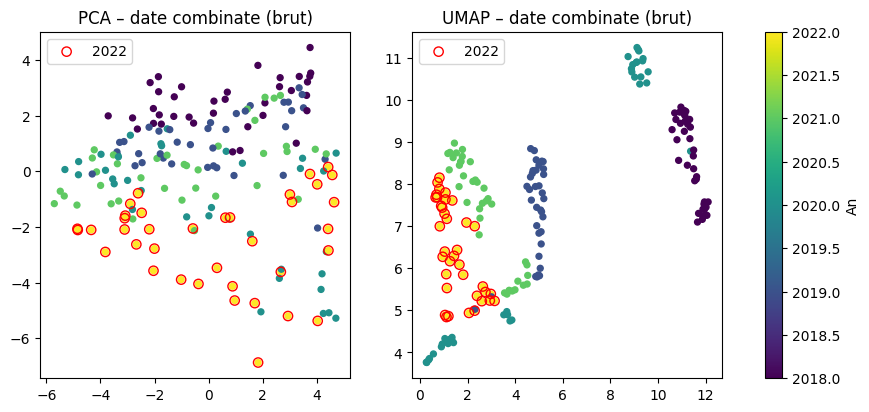

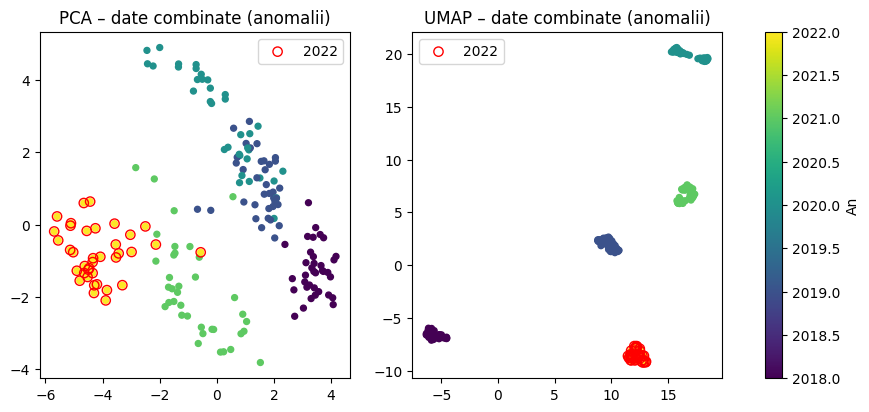

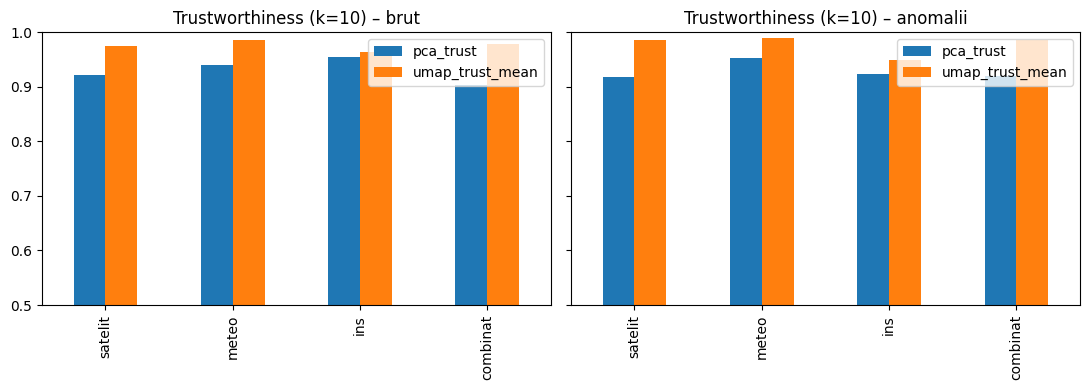

Fișiere de urcat în repo: matrice_X.csv, statistici_descriptive.csv, rezultate_CP3_*.csv, rezultate_CCA_LOYO.csv, fig_*.png


In [42]:
# G: figuri pentru slide
for var, D in VARIANTE.items():
    Z = Z_of(D, TOATE); T = PCA(2).fit_transform(Z)
    U = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=0).fit_transform(Z)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
    for a, E, nm in zip(ax, (T, U), ('PCA', 'UMAP')):
        sc = a.scatter(E[:, 0], E[:, 1], c=D.An, cmap='viridis', s=18)
        m22 = D.An.values == 2022
        a.scatter(E[m22, 0], E[m22, 1], facecolors='none', edgecolors='red', s=45, label='2022')
        a.set_title(f'{nm} – date combinate ({var})'); a.legend()
    fig.colorbar(sc, ax=ax, label='An'); plt.savefig(f'fig_proiectii_{var}.png', dpi=150, bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, (var, R) in zip(ax, REZ.items()):
    R[['pca_trust', 'umap_trust_mean']].plot.bar(ax=a)
    a.set_title(f'Trustworthiness (k={K_NN}) – {var}'); a.set_ylim(0.5, 1)
plt.tight_layout(); plt.savefig('fig_trustworthiness.png', dpi=150); plt.show()
print('Fișiere de urcat în repo: matrice_X.csv, statistici_descriptive.csv, rezultate_CP3_*.csv, rezultate_CCA_LOYO.csv, fig_*.png')